<a href="https://colab.research.google.com/github/satanu-ui/ECG-Signal-Classification-for-Arrhythmia-Detection/blob/main/Ecg_Signal_for_arrythmia_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Install Dependencies
We need the `wfdb` (Waveform Database) package to download and parse the MIT-BIH Arrhythmia Database directly from PhysioNet.

In [1]:
!pip install wfdb

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.9/16.9 MB 4.9 MB/s  0:00:03
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [wfdb]


In [13]:
import os
import wfdb

dataset_dir = './mit_bih_database'
os.makedirs(dataset_dir, exist_ok=True)

# Download the MIT-BIH Arrhythmia Database files from PhysioNet using wfdb
print("Downloading MIT-BIH Arrhythmia Database files...")
wfdb.dl_database('mitdb', dl_dir=dataset_dir, overwrite=False)
print("Download complete! Ready to load records.")

Generating record list for: 100
Generating record list for: 101
Generating record list for: 102
Generating record list for: 103
Generating record list for: 104
Generating record list for: 105
Generating record list for: 106
Generating record list for: 107
Generating record list for: 108
Generating record list for: 109
Generating record list for: 111
Generating record list for: 112
Generating record list for: 113
Generating record list for: 114
Generating record list for: 115
Generating record list for: 116
Generating record list for: 117
Generating record list for: 118
Generating record list for: 119
Generating record list for: 121
Generating record list for: 122
Generating record list for: 123
Generating record list for: 124
Generating record list for: 200
Generating record list for: 201
Generating record list for: 202
Generating record list for: 203
Generating record list for: 205
Generating record list for: 207
Generating record list for: 208
Generating record list for: 209
Generati

### 2. Download and Explore the MIT-BIH Arrhythmia Database
We will download the dataset files and write a Python script to load the records, extract ECG signals, and visualize some heartbeats along with their corresponding annotations (e.g., Normal, Left bundle branch block, Right bundle branch block, Premature ventricular contraction).

In [14]:
import os
import numpy as np
import pandas as pd
import wfdb

dataset_dir = './mit_bih_database'

# List of all records in the MIT-BIH database
records = [
    '100', '101', '102', '103', '104', '105', '106', '107', '108', '109',
    '111', '112', '113', '114', '115', '116', '117', '118', '119', '121',
    '122', '123', '124', '200', '201', '202', '203', '205', '207', '208',
    '209', '210', '212', '213', '214', '215', '217', '219', '220', '221',
    '222', '223', '228', '230', '231', '232', '233', '234'
]

# Map of AAMI EC57 classes
aami_classes = {
    'N': ['N', 'L', 'R', 'e', 'j'],
    'S': ['A', 'a', 'J', 'S'],
    'V': ['V', 'E'],
    'F': ['F'],
    'Q': ['/', 'f', 'Q', 'U']
}

class_map = {}
for category, symbols in aami_classes.items():
    for symbol in symbols:
        class_map[symbol] = category

window_size = 180
X = []
y = []

print("Processing records...")
for record_name in records:
    record_path = os.path.join(dataset_dir, record_name)

    # Check if record file exists in the directory
    if not os.path.exists(record_path + '.hea'):
         continue

    try:
        record = wfdb.rdrecord(record_path)
        annotation = wfdb.rdann(record_path, 'atr')

        # Use lead MLII (usually channel index 0)
        signal = record.p_signal[:, 0]

        # Standardize
        signal = (signal - np.mean(signal)) / np.std(signal)

        peaks = annotation.sample
        symbols = annotation.symbol

        for peak, symbol in zip(peaks, symbols):
            if symbol in class_map:
                if peak - window_size >= 0 and peak + window_size < len(signal):
                    segment = signal[peak - window_size : peak + window_size]
                    X.append(segment)
                    y.append(class_map[symbol])
    except Exception as e:
        print(f"Skipping record {record_name} due to: {e}")

X = np.array(X)
y = np.array(y)

print(f"\nTotal processed heartbeat segments: {X.shape[0]}")
print(f"Feature matrix shape: {X.shape}")
if len(y) > 0:
    print("Class distribution:\n", pd.Series(y).value_counts())
else:
    print("No heartbeats were processed. Please check if dataset files were fully extracted.")

Processing records...

Total processed heartbeat segments: 109438
Feature matrix shape: (109438, 360)
Class distribution:
 N    90582
Q     8038
V     7235
S     2781
F      802
Name: count, dtype: int64


### 4. Plot Sample Heartbeats
Let's visualize one representative heartbeat for each of the main classification categories.

In [11]:
import matplotlib.pyplot as plt
import numpy as np

unique_classes = np.unique(y)

if len(unique_classes) == 0:
    print("No heartbeat segments available to plot. Please check your data loading step.")
else:
    fig, axes = plt.subplots(len(unique_classes), 1, figsize=(10, 2 * len(unique_classes)), sharex=True)

    # Ensure axes is iterable even if there is only 1 class
    if len(unique_classes) == 1:
        axes = [axes]

    for i, cls in enumerate(unique_classes):
        idx = np.where(y == cls)[0][0]
        axes[i].plot(X[idx])
        axes[i].set_title(f"Class: {cls} (Example segment)")
        axes[i].grid(True)

    plt.xlabel("Sample index")
    plt.tight_layout()
    plt.show()

No heartbeat segments available to plot. Please check your data loading step.


### 8. Deep Learning Baseline: 1D Convolutional Neural Network (1D-CNN)
To better capture the temporal dynamics of ECG waveforms, we will build a 1D Convolutional Neural Network. We will start by formatting the inputs for Keras (`[samples, time_steps, channels]`) and encoding the labels into categorical vectors.

In [18]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, BatchNormalization, MaxPool1D, Flatten, Dense, Dropout
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder

# Ensure train-test split variables exist (in case cells are run out of order)
if 'X_train' not in globals() or 'y_train' not in globals():
    from sklearn.model_selection import train_test_split
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

# Encode target labels to integer classes
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

# Convert to categorical (one-hot encoding)
num_classes = len(label_encoder.classes_)
y_train_cat = to_categorical(y_train_encoded, num_classes)
y_test_cat = to_categorical(y_test_encoded, num_classes)

# Reshape X for 1D CNN: [samples, features, channels]
X_train_cnn = X_train[..., np.newaxis]
X_test_cnn = X_test[..., np.newaxis]

print(f"X_train shape for CNN: {X_train_cnn.shape}")
print(f"X_test shape for CNN: {X_test_cnn.shape}")

X_train shape for CNN: (87550, 360, 1)
X_test shape for CNN: (21888, 360, 1)


### 9. Build and Train the 1D-CNN Model
We will define a sequential 1D-CNN model architecture consisting of convolutional layers, batch normalization, pooling layers, dropout for regularization, and a dense layer with a softmax activation.

In [19]:
# Define 1D-CNN architecture
model = Sequential([
    Conv1D(64, kernel_size=6, activation='relu', input_shape=(X_train_cnn.shape[1], 1)),
    BatchNormalization(),
    MaxPool1D(pool_size=3, strides=2),

    Conv1D(128, kernel_size=3, activation='relu'),
    BatchNormalization(),
    MaxPool1D(pool_size=2, strides=2),

    Conv1D(256, kernel_size=3, activation='relu'),
    BatchNormalization(),
    MaxPool1D(pool_size=2, strides=2),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(num_classes, activation='softmax')
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 355, 64)        │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 355, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 177, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 175, 128)       │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 175, 128)       │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 87, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 85, 256)        │        98,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 85, 256)        │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 42, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 10752)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,376,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,502,533 (5.73 MB)

 Trainable params: 1,501,637 (5.73 MB)

 Non-trainable params: 896 (3.50 KB)

### 10. Fit and Evaluate Deep Learning Model
We will fit the network using early stopping to prevent overfitting, and evaluate its output against the test subset.

In [20]:
# Add early stopping
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

# Train the CNN model
history = model.fit(
    X_train_cnn, y_train_cat,
    epochs=20,
    batch_size=128,
    validation_split=0.1,
    callbacks=[early_stopping]
)

# Evaluate the model
test_loss, test_acc = model.evaluate(X_test_cnn, y_test_cat)
print(f"\nTest Accuracy: {test_acc:.4f}")

Epoch 1/20
616/616 ━━━━━━━━━━━━━━━━━━━━ 278s 447ms/step - accuracy: 0.9537 - loss: 0.1949 - val_accuracy: 0.9782 - val_loss: 0.0823
Epoch 2/20
616/616 ━━━━━━━━━━━━━━━━━━━━ 331s 461ms/step - accuracy: 0.9739 - loss: 0.1003 - val_accuracy: 0.9817 - val_loss: 0.0722
Epoch 3/20
616/616 ━━━━━━━━━━━━━━━━━━━━ 280s 455ms/step - accuracy: 0.9792 - loss: 0.0783 - val_accuracy: 0.9864 - val_loss: 0.0505
Epoch 4/20
616/616 ━━━━━━━━━━━━━━━━━━━━ 278s 451ms/step - accuracy: 0.9816 - loss: 0.0681 - val_accuracy: 0.9873 - val_loss: 0.0483
Epoch 5/20
616/616 ━━━━━━━━━━━━━━━━━━━━ 323s 454ms/step - accuracy: 0.9845 - loss: 0.0587 - val_accuracy: 0.9887 - val_loss: 0.0458
Epoch 6/20
616/616 ━━━━━━━━━━━━━━━━━━━━ 323s 456ms/step - accuracy: 0.9851 - loss: 0.0549 - val_accuracy: 0.9883 - val_loss: 0.0477
Epoch 7/20
616/616 ━━━━━━━━━━━━━━━━━━━━ 312s 440ms/step - accuracy: 0.9866 - loss: 0.0481 - val_accuracy: 0.9889 - val_loss: 0.0411
Epoch 8/20
616/616 ━━━━━━━━━━━━━━━━━━━━ 278s 452ms/step - accuracy: 0.9871 -

### 11. Evaluate the 1D-CNN Model
Let's generate the classification report and plot the confusion matrix for the 1D-CNN predictions on the test dataset.

684/684 ━━━━━━━━━━━━━━━━━━━━ 16s 24ms/step
1D-CNN Classification Report:

              precision    recall  f1-score   support

           F       0.95      0.72      0.82       160
           N       0.99      1.00      1.00     18117
           Q       1.00      1.00      1.00      1608
           S       0.98      0.83      0.90       556
           V       0.98      0.98      0.98      1447

    accuracy                           0.99     21888
   macro avg       0.98      0.90      0.94     21888
weighted avg       0.99      0.99      0.99     21888



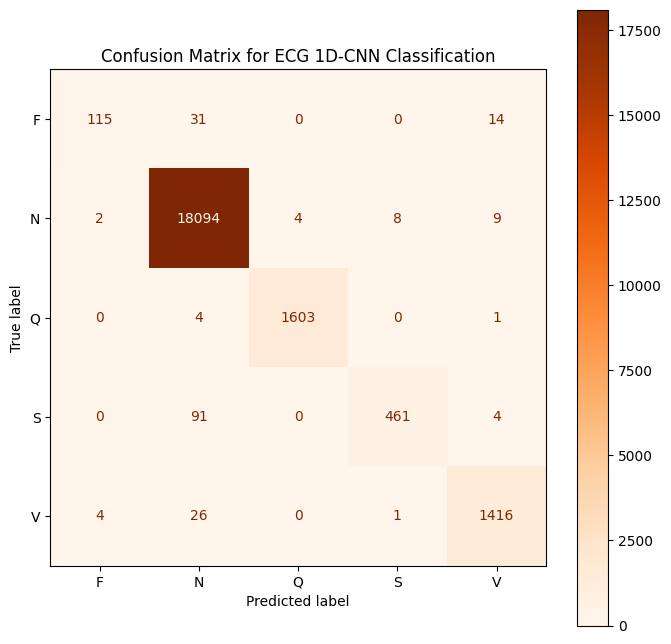

In [21]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Get model predictions
y_pred_cnn_probs = model.predict(X_test_cnn)
y_pred_cnn_encoded = np.argmax(y_pred_cnn_probs, axis=1)

# Decode back to original string classes
y_pred_cnn = label_encoder.inverse_transform(y_pred_cnn_encoded)

# Print classification report
print("1D-CNN Classification Report:\n")
print(classification_report(y_test, y_pred_cnn))

# Plot Confusion Matrix
fig, ax = plt.subplots(figsize=(8, 8))
cm_cnn = confusion_matrix(y_test, y_pred_cnn, labels=label_encoder.classes_)
disp_cnn = ConfusionMatrixDisplay(confusion_matrix=cm_cnn, display_labels=label_encoder.classes_)
disp_cnn.plot(cmap=plt.cm.Oranges, ax=ax, values_format='d')
plt.title("Confusion Matrix for ECG 1D-CNN Classification")
plt.show()

### 5. Train-Test Split and Handling Class Imbalance
We will perform a stratified split of the dataset to maintain class distribution across training and testing sets. We will use a Random Forest model with a cost-sensitive learning approach (`class_weight='balanced'`) to address the severe class imbalance.

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
import numpy as np

# Perform a stratified split to preserve class distribution proportions
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (87550, 360)
Testing set shape: (21888, 360)


### 6. Train the Machine Learning Model
We will initialize and train a Random Forest Classifier. To balance the contribution of the minority classes (like 'F' and 'S'), we will set `class_weight='balanced'`.

In [16]:
# Initialize Random Forest Classifier with balanced class weights
rf_model = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1)

print("Training the Random Forest model on the Kaggle dataset records...")
rf_model.fit(X_train, y_train)
print("Training complete!")

Training the Random Forest model on the Kaggle dataset records...
Training complete!


### 7. Evaluate the Model
We will predict on the test set and evaluate performance using precision, recall, f1-score, and a confusion matrix visualization.

Classification Report for Random Forest Baseline:

              precision    recall  f1-score   support

           F       0.91      0.61      0.73       160
           N       0.98      1.00      0.99     18117
           Q       1.00      0.95      0.97      1608
           S       0.99      0.65      0.79       556
           V       0.98      0.91      0.95      1447

    accuracy                           0.98     21888
   macro avg       0.97      0.82      0.88     21888
weighted avg       0.98      0.98      0.98     21888



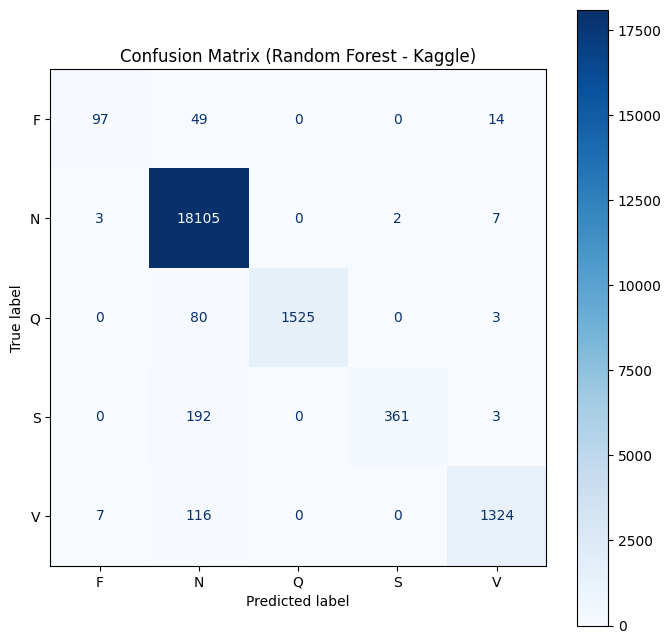

In [17]:
# Predict on Kaggle test subset
y_pred = rf_model.predict(X_test)

# Print classification report
print("Classification Report for Random Forest Baseline:\n")
print(classification_report(y_test, y_pred))

# Plot Confusion Matrix
fig, ax = plt.subplots(figsize=(8, 8))
cm = confusion_matrix(y_test, y_pred, labels=rf_model.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=rf_model.classes_)
disp.plot(cmap=plt.cm.Blues, ax=ax, values_format='d')
plt.title("Confusion Matrix (Random Forest - Kaggle)")
plt.show()